# Slobodna parkirna mjesta (YOLO), verzija 2

Program na snimci parkinga prepoznaje i prati aute, i za svako označeno parkirno mjesto određuje je li slobodno ili zauzeto.

**Što sam promijenio u odnosu na prvu verziju:**

1. **Zona s drvećem.** Na lijevom dijelu parkinga drveće djelomično skriva aute, pa ih model tamo često ne vidi.
   Sliku zato dijelim na dvije zone, a u zoni s drvećem koristim niži prag sigurnosti i veću rezoluciju.
2. **Bez zgrade na lijevom rubu.** Na lijevom rubu slike je zgrada, a model ju je (s niskim pragom u zoni s drvećem)
   označavao kao vozilo. Detekcije čije je središte u tom rubu izbacujem. Auti koji voze po cesti i dalje se prate.
3. **Bez duplih oznaka.** Isti auto je znao imati 2 do 3 pravokutnika: jednom jer su ga našle obje zone (zone se preklapaju),
   a jednom jer ga je model istovremeno prepoznao kao `car` i kao `truck`. Sad preklapajuće pravokutnike spajam u jedan.
4. **Vlastito praćenje auta.** Ugrađeni tracker je često gubio aute iza drveća i davao im nove ID-eve. Napisao sam
   jednostavan tracker za parking: auto se pamti i kad ga model nekoliko kadrova ne vidi, a novi auto se prikaže tek
   kad ga model vidi u par kadrova zaredom, pa slučajne lažne detekcije ne bljeskaju.
5. **Video uživo.** Dok se video obrađuje, rezultat se prikazuje u zasebnom prozoru.
6. **Prag sigurnosti stvarno radi.** U prvoj verziji sam postavljao `model.conf = 0.20`, ali to u novom
   Ultralytics API-ju nema nikakav učinak (to je bio način iz YOLOv5). Model je cijelo vrijeme koristio zadani prag 0.25.
   Sad prag šaljem direktno u `predict()`.
7. **Točniji broj slobodnih mjesta.** Prije sam brojao aute koji stoje na mjestima, pa se mjesto s dvije detekcije
   brojalo dvaput. Sad brojim zauzeta mjesta, a ne aute.

8. **Manje treptanja** zauzetosti: mjesto je zauzeto ako je zauzeto u većini zadnjih 10 kadrova.


## Postavke

In [18]:
import os
from collections import deque

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu128
CUDA: True


In [ ]:
VIDEO = r"C:\Users\Marinko\Desktop\parking3.mp4"
IZLAZ = r"C:\YOLO\parking_v2.mp4"

# zone
LIJEVI_UDIO = 0.30      # lijevih 30 % slike je zona s drvećem
PREKLOP = 80            # zone se preklapaju 80 px da auto na granici ne bude prerezan
CONF_LIJEVO = 0.20      # niži prag jer su auti djelomično skriveni
CONF_DESNO = 0.30
IMGSZ_LIJEVO = 1280     # veća rezolucija za zonu s drvećem
IMGSZ_DESNO = 640       # zadana vrijednost
VOZILA = [2, 3, 5, 7]   # COCO klase: car, motorcycle, bus, truck


LIJEVI_RUB = 150        # prvih 150 px s lijeva je zgrada, tamo ne tražim vozila
IGNORIRAJ = []          
SAMO_PARKING = False    
MARGINA = 60            


POTVRDA = 3             # novi auto se prikaže tek kad ga model vidi u 3 framea
PAMTI_KADROVA = 60      # koliko dugo pamtim auto koji model ne vidi (60 kadrova = 2 s pri 30 fps)
PRIKAZI_IZGUBLJENE = 15 # izgubljeni auto i dalje crtam još 15 kadrova (npr. kad je iza drveća)
IOU_PRAG = 0.3          # koliko se pravokutnik mora poklopiti s prethodnim da bude isti auto

GLADENJE = 10           # mjesto je zauzeto ako je zauzeto u većini zadnjih 10 kadrova

PRIKAZ_UZIVO = True     # prozor s videom dok se obrađuje (q = prekid
MAX_KADROVA = None      # npr. 300 za brzu probu (~10 s videa), None = cijeli video

# boje su u BGR redoslijedu (plava, zelena, crvena), jer tako radi OpenCV
CRVENA = (0, 0, 255)      # zauzeto mjesto
ZELENA = (0, 255, 0)      # slobodno mjesto
PLAVA = (255, 120, 0)     # vozila
ZUTA = (0, 255, 255)      # granica zona (samo na slici za provjeru)
BIJELA = (255, 255, 255)
SIVA = (128, 128, 128)

Parkirna mjesta su ista kao u prvoj verziji: svako je četverokut zadan s 4 točke (u pikselima), jer su zbog
perspektive kamere mjesta ukošena. Ako koristim drugi video, ove koordinate treba ponovno odrediti.

In [20]:
PARKING_MJESTA = {
    "rect11": [[1580, 880], [1750, 980], [1745, 1070], [1560, 1040]],
    "rect12": [[1450, 805], [1570, 860], [1540, 1030], [1400, 930]],
    "rect13": [[1345, 725], [1445, 785], [1385, 915], [1270, 835]],
    "rect14": [[1240, 670], [1335, 720], [1260, 825], [1170, 750]],
    "rect15": [[1160, 615], [1235, 660], [1155, 750], [1080, 690]],
    "rect16": [[1085, 575], [1150, 610], [1070, 680], [1005, 635]],
    "rect17": [[1020, 530], [1080, 570], [1000, 625], [950, 585]],
    "rect18": [[970, 500], [1010, 525], [935, 580], [890, 545]],
    "rect19": [[925, 465], [960, 490], [885, 530], [845, 510]],
    "rect10": [[870, 445], [905, 455], [830, 500], [800, 475]],
    "rect111": [[835, 415], [875, 437], [790, 470], [760, 450]],

    "rect21": [[490, 805], [660, 700], [695, 760], [530, 880]],
    "rect22": [[720, 765], [760, 830], [575, 985], [535, 900]],
    "rect23": [[775, 845], [835, 925], [655, 1075], [585, 1010]],
    "rect24": [[620, 640], [650, 680], [480, 785], [465, 730]],
}
PARKING_MJESTA = {k: np.array(v, dtype=np.float32) for k, v in PARKING_MJESTA.items()}
IGNORIRAJ = [np.array(z, dtype=np.float32) for z in IGNORIRAJ]
print("Broj parkirnih mjesta:", len(PARKING_MJESTA))

Broj parkirnih mjesta: 15


## Video

In [21]:
cap = cv2.VideoCapture(VIDEO)
print("Video otvoren:", cap.isOpened())

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 30      # neki videi ne javljaju fps, onda uzmem 30
ukupno_kadrova = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

ret, frame1 = cap.read()
cap.release()
if not ret:
    raise RuntimeError("Nije uspjelo učitati kadar, provjeri putanju do videa")

granica = int(width * LIJEVI_UDIO)

print(f"Rezolucija: {width}x{height}, {fps:.1f} fps, {ukupno_kadrova} kadrova ({ukupno_kadrova / fps:.0f} s)")
print("Granica zona na x =", granica)

Video otvoren: True
Rezolucija: 1920x1080, 30.0 fps, 1406 kadrova (47 s)
Granica zona na x = 576


## Crtanje

In [22]:
def nacrtaj_mjesta(slika, zauzeta):
    # prozirna ispuna: crveno zauzeto, zeleno slobodno
    sloj = slika.copy()
    for ime, poly in PARKING_MJESTA.items():
        cv2.fillPoly(sloj, [poly.astype(np.int32)], CRVENA if ime in zauzeta else ZELENA)
    cv2.addWeighted(sloj, 0.3, slika, 0.7, 0, dst=slika)

    for ime, poly in PARKING_MJESTA.items():
        boja = CRVENA if ime in zauzeta else ZELENA
        cv2.polylines(slika, [poly.astype(np.int32)], isClosed=True, color=boja, thickness=2)


def nacrtaj_vozila(slika, vozila):
    """vozila: lista (x1, y1, x2, y2, oznaka)"""
    for x1, y1, x2, y2, oznaka in vozila:
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
        cv2.rectangle(slika, (x1, y1), (x2, y2), PLAVA, 2)

        # oznaka s plavom pozadinom iznad auta, da se lakše čita
        (w, h), _ = cv2.getTextSize(oznaka, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(slika, (x1, y1 - h - 8), (x1 + w + 6, y1), PLAVA, -1)
        cv2.putText(slika, oznaka, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, BIJELA, 1, cv2.LINE_AA)


def prikazi(slika, naslov, mreza=False):
    plt.figure(figsize=(15, 8))
    plt.imshow(cv2.cvtColor(slika, cv2.COLOR_BGR2RGB))
    plt.title(naslov)
    if mreza:
        plt.grid(True, alpha=0.4)
    else:
        plt.axis("off")
    plt.show()

Provjera prije obrade: poklapaju li se parkirna mjesta s videom, gdje je granica zona (žuto) i koji lijevi rub
izbacujem (sivo zatamnjeno). Ako zgrada viri izvan sivog dijela, povećam `LIJEVI_RUB`.

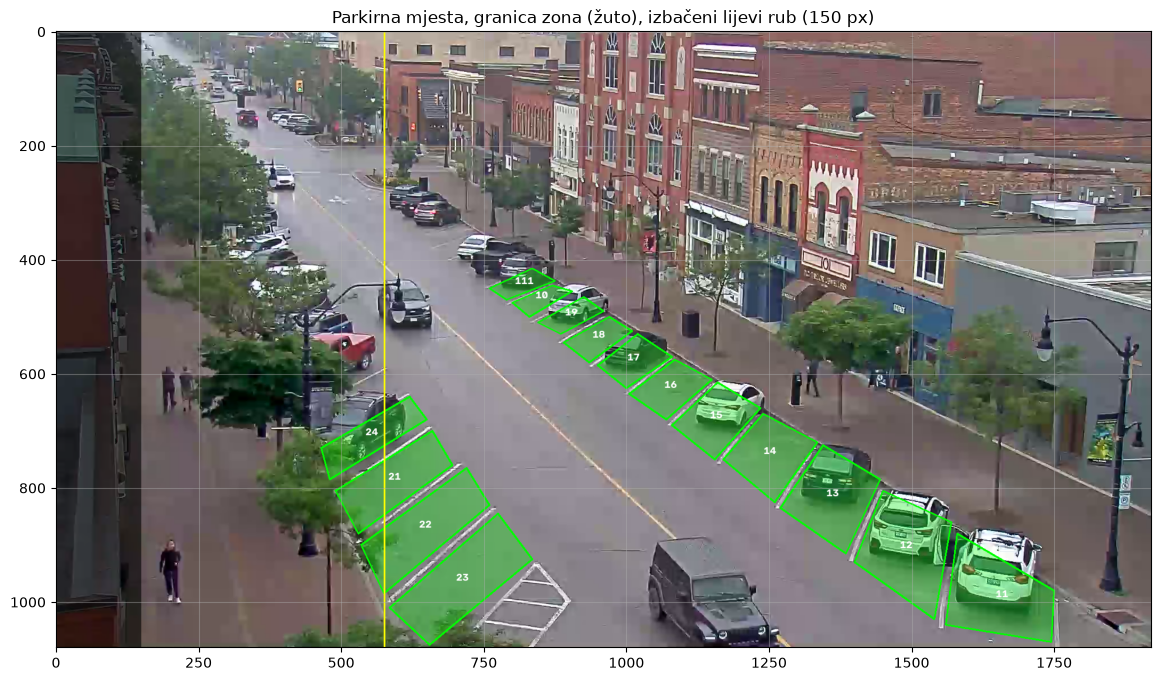

In [23]:
provjera = frame1.copy()
nacrtaj_mjesta(provjera, zauzeta=set())
cv2.line(provjera, (granica, 0), (granica, height), ZUTA, 2)

# zatamni lijevi rub koji izbacujem
provjera[:, :LIJEVI_RUB] = (provjera[:, :LIJEVI_RUB] * 0.4).astype(np.uint8)

for ime, poly in PARKING_MJESTA.items():
    cx, cy = poly.mean(axis=0).astype(int)
    cv2.putText(provjera, ime[4:], (cx - 10, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, BIJELA, 2)

for z in IGNORIRAJ:
    cv2.polylines(provjera, [z.astype(np.int32)], True, SIVA, 3)

prikazi(provjera, f"Parkirna mjesta, granica zona (žuto), izbačeni lijevi rub ({LIJEVI_RUB} px)", mreza=True)

## Detekcija

Postupak za svaki kadar:
1. **Dvije zone.** Lijevu (s drvećem) i desnu zonu šaljem modelu posebno, svaku sa svojim postavkama. Koordinate desne zone
   pomičem (`pomak_x`) jer YOLO desnu zonu vidi kao zasebnu sliku koja počinje od x = 0.
2. **`agnostic_nms=True`**: model inače preklapajuće pravokutnike spaja samo ako su iste klase, pa je isti auto mogao dobiti
   i `car` i `truck`. S ovom opcijom spaja i različite klase.
3. **Filtriranje**: izbacujem detekcije na lijevom rubu (zgrada) i u zonama `IGNORIRAJ`.
4. **Spajanje duplikata**: auto u preklopu zona nađu obje zone. Ako se dva pravokutnika jako preklapaju, ili je jedan
   skoro cijeli unutar drugog (npr. model je našao pola auta iza drveća i cijeli auto), zadržavam samo sigurniji.

 YOLO svaku sliku prije detekcije ionako smanji na `imgsz` (zadano 640). Zato povećavam `imgsz`, jer tada model stvarno radi na većoj rezoluciji.

In [24]:
model = YOLO("yolo12n.pt")
print("Vozila koja gledam:", [model.names[k] for k in VOZILA])


def iou(a, b):
    """Koliko se dva pravokutnika preklapaju (0 = nikako, 1 = potpuno)."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    presjek = max(0, x2 - x1) * max(0, y2 - y1)
    pa = (a[2] - a[0]) * (a[3] - a[1])
    pb = (b[2] - b[0]) * (b[3] - b[1])
    return presjek / (pa + pb - presjek + 1e-9), presjek / (min(pa, pb) + 1e-9)


def zadrzi(tocka):
    t = (float(tocka[0]), float(tocka[1]))
    if t[0] < LIJEVI_RUB:
        return False
    if any(cv2.pointPolygonTest(z, t, False) >= 0 for z in IGNORIRAJ):
        return False
    if SAMO_PARKING:
        # pointPolygonTest s measureDist=True vraća udaljenost: pozitivno unutra, negativno izvana
        return any(cv2.pointPolygonTest(p, t, True) >= -MARGINA for p in PARKING_MJESTA.values())
    return True


def detekcije_zone(slika, conf, imgsz, pomak_x):
    r = model.predict(slika, conf=conf, imgsz=imgsz, classes=VOZILA, agnostic_nms=True, verbose=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        return []
    return [(x1 + pomak_x, y1, x2 + pomak_x, y2, c)
            for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())]


def spoji_duplikate(detekcije, iou_prag=0.45, unutar_prag=0.7):
    zadrzane = []
    for d in sorted(detekcije, key=lambda d: d[4], reverse=True):   # od najsigurnije
        if all(iou(d, z)[0] < iou_prag and iou(d, z)[1] < unutar_prag for z in zadrzane):
            zadrzane.append(d)
    return zadrzane


def detektiraj(frame):
    kraj_lijevo = min(granica + PREKLOP, width)
    pocetak_desno = max(granica - PREKLOP, 0)

    sve = (detekcije_zone(frame[:, :kraj_lijevo], CONF_LIJEVO, IMGSZ_LIJEVO, 0)
           + detekcije_zone(frame[:, pocetak_desno:], CONF_DESNO, IMGSZ_DESNO, pocetak_desno))

    sve = [d for d in sve if zadrzi(((d[0] + d[2]) / 2, (d[1] + d[3]) / 2))]
    return spoji_duplikate(sve)

Vozila koja gledam: ['car', 'motorcycle', 'bus', 'truck']


## Praćenje

Ugrađeni tracker u Ultralyticsu je napravljen za objekte koji se puno kreću (ljudi, promet). Na parkingu auti uglavnom
stoje, ali ih drveće povremeno sakrije, pa je ugrađeni tracker često davao novi ID autu koji je samo na trenutak nestao.

Zato koristim jednostavan tracker:
- za svaki auto pamtim i **brzinu**, pa u novom kadru očekujem auto malo dalje u smjeru kretanja (auti koji stoje imaju brzinu ~0)
- auto iz novog kadra povezujem s autom iz prethodnih kadrova ako se pravokutnik dovoljno preklapa s očekivanim položajem (`IOU_PRAG`)
- auto koji model ne vidi **pamtim još `PAMTI_KADROVA` kadrova** i nastavljam ga pomicati prema brzini, pa kad se ponovno pojavi, dobije isti ID
- novi auto se prikaže tek kad ga model vidi u `POTVRDA` kadrova, pa lažna detekcija u jednom kadru ne bljesne
- pravokutnik malo izglađujem (70 % novi položaj, 30 % stari), da ne podrhtava, a da i dalje prati aute koji voze

In [25]:
def sredina(box):
    return ((box[0] + box[2]) / 2, (box[1] + box[3]) / 2)


class ParkingTracker:
    def __init__(self):
        self.tragovi = {}       # interni broj -> podaci o autu
        self.sljedeci = 0
        self.sljedeci_id = 1    # ID koji se prikazuje, dodjeljuje se tek kad je auto potvrđen

    def azuriraj(self, detekcije):
        # 1) predviđanje: svaki auto pomaknem za njegovu brzinu (auti koji stoje imaju brzinu ~0)
        for t in self.tragovi.values():
            vx, vy = t["v"]
            t["box"] = [t["box"][0] + vx, t["box"][1] + vy, t["box"][2] + vx, t["box"][3] + vy]

        # 2) povezivanje: svi parovi (auto, detekcija) koji se dovoljno preklapaju, od najboljeg
        parovi = sorted(
            ((iou(t["box"], d)[0], k, j) for k, t in self.tragovi.items() for j, d in enumerate(detekcije)),
            reverse=True,
        )
        povezani_t, povezane_d = set(), set()
        for v, k, j in parovi:
            if v < IOU_PRAG:
                break
            if k in povezani_t or j in povezane_d:
                continue
            t = self.tragovi[k]
            novi = list(detekcije[j][:4])

            # brzinu ispravim za razliku između predviđenog i stvarnog položaja
            (px, py), (nx, ny) = sredina(t["box"]), sredina(novi)
            t["v"] = [t["v"][0] + 0.3 * (nx - px), t["v"][1] + 0.3 * (ny - py)]
            t["box"] = [0.3 * s + 0.7 * n for s, n in zip(t["box"], novi)]   # izglađivanje

            t["vidjen"] += 1
            t["izgubljen"] = 0
            if t["id"] is None and t["vidjen"] >= POTVRDA:
                t["id"] = self.sljedeci_id
                self.sljedeci_id += 1
            povezani_t.add(k)
            povezane_d.add(j)

        # 3) auti koje model u ovom kadru nije vidio: pamtim ih, a brzinu polako smanjujem
        for k in list(self.tragovi):
            if k not in povezani_t:
                t = self.tragovi[k]
                t["izgubljen"] += 1
                t["v"] = [t["v"][0] * 0.9, t["v"][1] * 0.9]
                if t["izgubljen"] > (2 if t["id"] is None else PAMTI_KADROVA):
                    del self.tragovi[k]

        # 4) nove detekcije koje ne pripadaju nijednom autu
        for j, d in enumerate(detekcije):
            if j not in povezane_d:
                self.tragovi[self.sljedeci] = {"box": list(d[:4]), "v": [0.0, 0.0],
                                               "vidjen": 1, "izgubljen": 0, "id": None}
                self.sljedeci += 1

        # vraćam potvrđene aute koji su viđeni nedavno
        return [(*t["box"], t["id"]) for t in self.tragovi.values()
                if t["id"] is not None and t["izgubljen"] <= PRIKAZI_IZGUBLJENE]

    def broj_auta(self):
        return self.sljedeci_id - 1

In [26]:
def zauzeta_mjesta(vozila):
    """Mjesto je zauzeto ako središte nekog vozila pada unutar njega."""
    zauzeta = set()
    for x1, y1, x2, y2, *_ in vozila:
        sredina = (float((x1 + x2) / 2), float((y1 + y2) / 2))
        for ime, poly in PARKING_MJESTA.items():
            if cv2.pointPolygonTest(poly, sredina, False) >= 0:
                zauzeta.add(ime)
                break
    return zauzeta

## Usporedba na prvom kadru

**Verzija 1:** cijela slika, samo klasa `car`, zadani prag 0.25 (jer `model.conf` nije imao učinka), bez filtriranja.

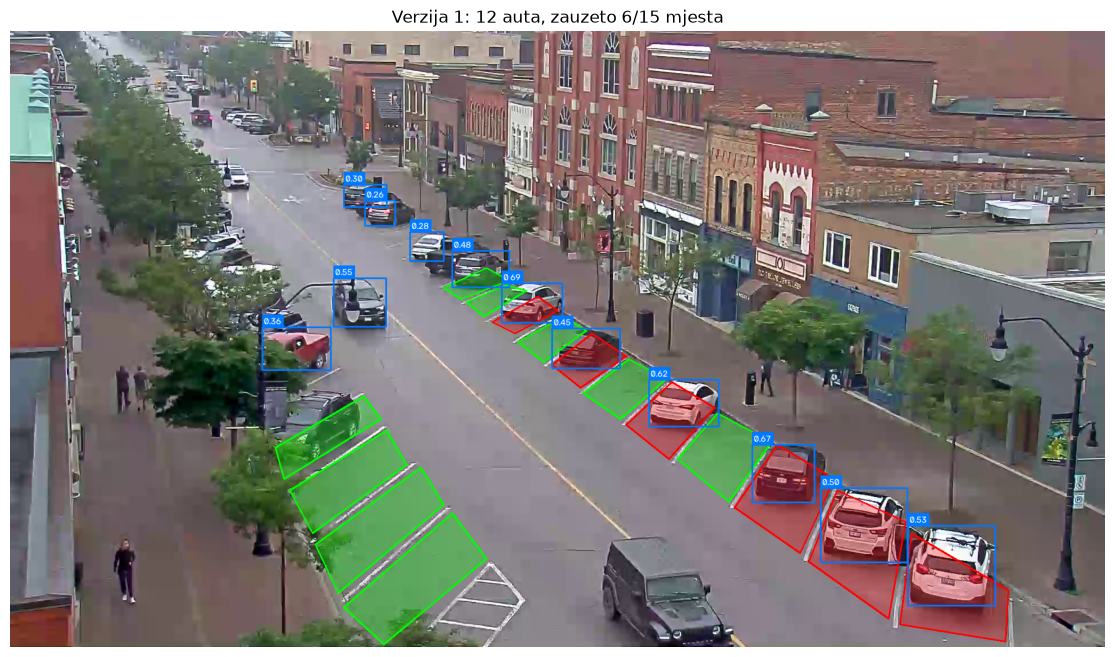

In [27]:
r = model.predict(frame1, classes=[2], verbose=False)[0]
det_v1 = [(*box, f"{c:.2f}") for box, c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())]
zauzeta_v1 = zauzeta_mjesta(det_v1)

slika_v1 = frame1.copy()
nacrtaj_mjesta(slika_v1, zauzeta_v1)
nacrtaj_vozila(slika_v1, det_v1)
prikazi(slika_v1, f"Verzija 1: {len(det_v1)} auta, zauzeto {len(zauzeta_v1)}/{len(PARKING_MJESTA)} mjesta")

**Verzija 2:** dvije zone, sva vozila, bez lijevog ruba sa zgradom i bez duplikata.

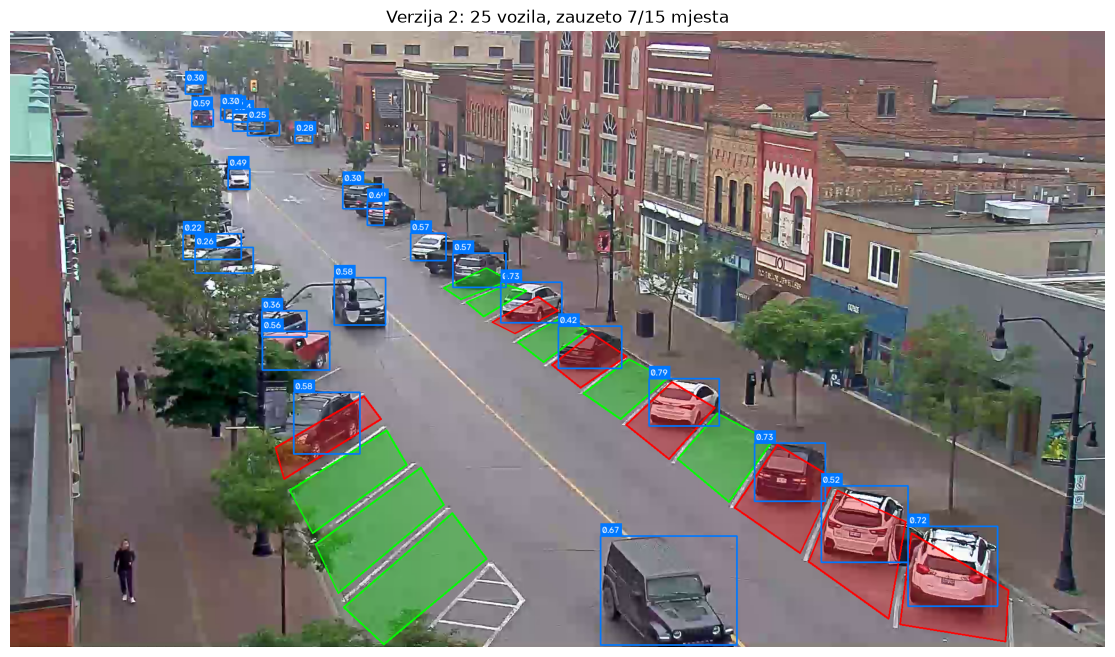

In [28]:
det_v2 = detektiraj(frame1)
zauzeta_v2 = zauzeta_mjesta(det_v2)

slika_v2 = frame1.copy()
nacrtaj_mjesta(slika_v2, zauzeta_v2)
nacrtaj_vozila(slika_v2, [(*d[:4], f"{d[4]:.2f}") for d in det_v2])
prikazi(slika_v2, f"Verzija 2: {len(det_v2)} vozila, zauzeto {len(zauzeta_v2)}/{len(PARKING_MJESTA)} mjesta")

## Obrada cijelog videa

U videu su parkirna mjesta zelena (slobodno) ili crvena (zauzeto), a vozila plava s ID-em.
Rezultat se sprema u video, a ako je `PRIKAZ_UZIVO = True`, prikazuje se i u prozoru dok traje obrada
(tipka **q** prekida obradu, a dosad obrađeni dio ostaje spremljen).

Uz tracker, zauzetost mjesta dodatno izglađujem: mjesto je zauzeto ako je zauzeto u više od pola zadnjih `GLADENJE` kadrova.

In [30]:
tracker = ParkingTracker()

cap = cv2.VideoCapture(VIDEO)
os.makedirs(os.path.dirname(IZLAZ) or ".", exist_ok=True)
out = cv2.VideoWriter(IZLAZ, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

povijest = {ime: deque(maxlen=GLADENJE) for ime in PARKING_MJESTA}
statistika = []
broj = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    detekcije = detektiraj(frame)
    vozila = tracker.azuriraj(detekcije)
    zauzeta_sad = zauzeta_mjesta(vozila)

    for ime in PARKING_MJESTA:
        povijest[ime].append(ime in zauzeta_sad)
    zauzeta = {ime for ime, h in povijest.items() if sum(h) > len(h) / 2}
    slobodno = len(PARKING_MJESTA) - len(zauzeta)

    # crtanje
    nacrtaj_mjesta(frame, zauzeta)
    nacrtaj_vozila(frame, [(*v[:4], f"#{v[4]}") for v in vozila])

    cv2.rectangle(frame, (30, 20), (560, 150), (0, 0, 0), -1)
    cv2.putText(frame, f"Slobodno: {slobodno}/{len(PARKING_MJESTA)}", (50, 75),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, ZELENA, 3, cv2.LINE_AA)
    cv2.putText(frame, f"Zauzeto: {len(zauzeta)}   Vozila: {len(vozila)}", (50, 125),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, BIJELA, 2, cv2.LINE_AA)

    out.write(frame)

    if PRIKAZ_UZIVO:
        try:
            cv2.imshow("Parking", cv2.resize(frame, (width // 2, height // 2)))
            if cv2.waitKey(1) & 0xFF == ord("q"):
                print("Prekinuto tipkom q")
                break
        except Exception:   # u Colabu i bez ekrana imshow ne radi
            print("Prozor se ne može otvoriti (npr. u Colabu), nastavljam bez prikaza")
            PRIKAZ_UZIVO = False

    red = {"kadar": broj, "sekunda": broj / fps, "slobodno": slobodno,
           "detekcija": len(detekcije), "vozila": len(vozila)}
    for ime in PARKING_MJESTA:
        red[ime] = int(ime in zauzeta)
        red[ime + "_sirovo"] = int(ime in zauzeta_mjesta(detekcije))
    statistika.append(red)

    broj += 1
    if broj % 100 == 0:
        print(f"{broj}/{ukupno_kadrova} kadrova")
    if MAX_KADROVA and broj >= MAX_KADROVA:
        break

cap.release()
out.release()
if PRIKAZ_UZIVO:
    cv2.destroyAllWindows()
print(f"Gotovo! Obrađeno {broj} kadrova, spremljeno: {IZLAZ}")

100/1406 kadrova
200/1406 kadrova
300/1406 kadrova
400/1406 kadrova
500/1406 kadrova
600/1406 kadrova
700/1406 kadrova
800/1406 kadrova
900/1406 kadrova
1000/1406 kadrova
1100/1406 kadrova
1200/1406 kadrova
1300/1406 kadrova
1400/1406 kadrova
Gotovo! Obrađeno 1406 kadrova, spremljeno: C:\YOLO\parking_v2.mp4


In [31]:
if os.name == "nt":
    os.startfile(IZLAZ)
else:
    print("Video je spremljen u", IZLAZ)